# Week 7 — Lab: K-means Clustering and PCA

**Course 04224 · Programming for Artificial Intelligence and Data Science**
Hung Vuong University, Ho Chi Minh City · Faculty of Engineering and Technology

**Learning outcomes:** CLO5; CLO4 — communicate and visualize results.
**Duration:** 3 periods, about **150 minutes**. Synthetic teaching data are read
from `../lab_data/khachhang.csv`; no network is needed after installing libraries.

**Plan:** 1. Scale (30′) · 2. Choose k (40′) · 3. Cluster profiles (35′) · 4. PCA (45′).

**Submit:** rename to `Week07_Lab_<StudentID>.ipynb`.
Complete every `# TODO`, **Restart & Run All**, and keep outputs and figures.
Include the k-selection table/plots, cluster profiles, PCA variance curve, 2D projection and interpretation.

## Before you start
Start Jupyter in `lab_exercises/`. Use `random_state=42` and run cells in order.
Each `# TODO` is explained in the preceding text. Replace `...` with your code.
Shape, probability and data-integrity checks must pass; model scores are observations,
not targets to force your answer to match. Rankings and timings can vary by version/hardware.

Customer data: `thang_gan_nhat` = months since the last order;
`tong_chi_tieu` = total spending (VND); `so_don` = order count;
`so_ticket_ho_tro` = support-ticket count. `roi_bo=1` means churn.
`ma_kh` is an identifier; categorical `kenh_ua_thich` and `tinh_tp` are outside
this lab's scope. Keep both the label and identifier out of the feature matrix.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                            roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
FEATURES = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
DATA_DIR = Path("../lab_data")
if not (DATA_DIR / "khachhang.csv").is_file():
    raise FileNotFoundError(f"Start Jupyter in lab_exercises/. Current folder: {Path.cwd()}")
customers = pd.read_csv(DATA_DIR / "khachhang.csv")
assert customers.shape == (1500, 8)
assert customers["ma_kh"].is_unique
assert not customers[FEATURES + ["roi_bo"]].isna().any().any()
X = customers[FEATURES].copy()
y = customers["roi_bo"].copy()
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
    "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Shape:", X.shape, "| churn fraction:", round(y.mean(), 4))
print(customers[FEATURES].describe().round(2).to_string())

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

Python: 3.12.6 | numpy: 2.5.3 | pandas: 3.0.5 | sklearn: 1.9.1
Shape: (1500, 4) | churn fraction: 0.2087
       thang_gan_nhat  tong_chi_tieu   so_don  so_ticket_ho_tro
count         1500.00        1500.00  1500.00           1500.00
mean            14.20     7793408.00     5.98              1.48
std              6.84     4637241.09     2.45              1.13
min              0.00      222000.00     0.00              0.00
25%              9.40     4382250.00     4.00              0.00
50%             14.30     6947500.00     6.00              1.00
75%             18.90    10196500.00     8.00              2.00
max             39.20    34434000.00    19.00              3.00


## Task 1 — Distance and units (30 min)
This is an **exploratory description of the 1500 current customers**, not a future
prediction benchmark. Fit scaler/PCA on all X here. If PCA is used before a predictive
model elsewhere, fit it inside the training split/fold.
Never use `roi_bo` to fit or select k; churn labels are not segmentation ground truth.
**1.1** Fit `StandardScaler` on the four numeric features and obtain `Z`; check mean/std.
**1.2** For `k=4, n_init=10`, fit K-means on raw X and Z. Compare silhouettes
**both measured in Z** for a shared geometry. Change VND to million VND and fit a third raw model.
Compare partitions with adjusted Rand index (ARI), not direct equality of cluster IDs.

In [2]:
# TODO 1.1
scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert Z.shape == (1500, 4)
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1, atol=1e-10)
print("Raw feature SD:", X.std(ddof=0).to_dict())

# TODO 1.2
raw_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
scaled_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
X_million = X.copy()
X_million["tong_chi_tieu"] /= 1_000_000
million_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_million)
for name, labels in [("raw VND", raw_km.labels_), ("standardized", scaled_km.labels_),
                    ("raw million VND", million_km.labels_)]:
    print(name, "silhouette in Z:", round(silhouette_score(Z, labels, sample_size=1000,
                                                        random_state=RANDOM_STATE), 4))
print("ARI raw VND vs raw million VND:", adjusted_rand_score(raw_km.labels_, million_km.labels_))
print("ARI raw VND vs standardized:", adjusted_rand_score(raw_km.labels_, scaled_km.labels_))

Raw feature SD: {'thang_gan_nhat': 6.840595003035595, 'tong_chi_tieu': 4635695.081596286, 'so_don': 2.4477744994177875, 'so_ticket_ho_tro': 1.132}
raw VND silhouette in Z: 0.059
standardized silhouette in Z: 0.2082
raw million VND silhouette in Z: 0.1222
ARI raw VND vs raw million VND: 0.13838923382326287
ARI raw VND vs standardized: 0.12958345013713857


**Write 1:** which column dominates raw distances? Does changing units change information? Why are inertias from different unit systems not directly comparable?

Trong dữ liệu gốc, đặc trưng tong_chi_tieu (Tổng chi tiêu) có giá trị lên tới hàng chục triệu, lớn hơn rất nhiều so với các đặc trưng khác. Do thuật toán K-means sử dụng khoảng cách hình học (thường là khoảng cách Euclid) để tối ưu hóa, sự chênh lệch lớn về thang đo này sẽ khiến tong_chi_tieu chi phối hoàn toàn kết quả phân cụm, làm mất đi ý nghĩa của các đặc trưng có giá trị nhỏ

Việc chuyển đổi đơn vị từ VNĐ sang triệu VNĐ bản chất không làm thay đổi lượng thông tin thống kê của biến số, nhưng lại làm thay đổi cấu trúc không gian khoảng cách giữa các điểm dữ liệu. Do K-means rất nhạy cảm với khoảng cách tuyệt đối, việc đổi đơn vị đã dẫn đến sự thay đổi hoàn toàn trong kết quả phân hoạch chỉ số ARI giữa hai mô hình ở mức rất thấp

Giá trị Quán tính (Inertia - tổng bình phương khoảng cách từ điểm dữ liệu đến tâm cụm) không thể được sử dụng để so sánh chéo giữa hai hệ thống đơn vị khác nhau vì chúng không cùng một không gian đo lường. Để phân cụm đa hướng một cách công bằng, toàn bộ dữ liệu bắt buộc phải được chuẩn hóa về chung một phân phối thông qua StandardScaler

## Task 2 — Choose k with evidence (40 min)
**2.1** Sweep `k=2..8`, `n_init=10`, seed 42 on Z. Store the model, inertia and silhouette
(`sample_size=1000`, seed 42). Plot elbow and silhouette in separate panels with separate y axes.
**2.2** Suggest k by the highest silhouette, then set `chosen_k` using your own argument
(use the suggestion by default). Consider separation, cluster sizes and the intended use.
Inertia usually decreases with k, so the largest k is not automatically best. There is no hidden “correct” k.

 k   inertia  silhouette
 2 4790.2406      0.2171
 3 4065.9802      0.2173
 4 3515.6035      0.2082
 5 3065.3098      0.2088
 6 2778.2419      0.2042
 7 2569.7911      0.2124
 8 2416.2696      0.2099


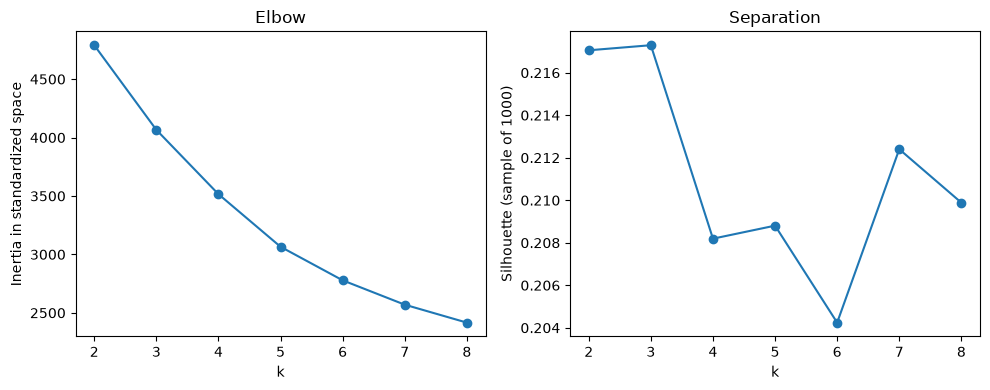

Suggested: 3 | chosen: 3
Cluster sizes: {0: 601, 1: 296, 2: 603}


In [3]:
# TODO 2.1
cluster_models, k_rows = {}, []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    cluster_models[k] = km
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_, sample_size=1000, random_state=RANDOM_STATE)})
k_table = pd.DataFrame(k_rows)
print(k_table.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_table["k"], k_table["inertia"], "o-")
axes[0].set(xlabel="k", ylabel="Inertia in standardized space", title="Elbow")
axes[1].plot(k_table["k"], k_table["silhouette"], "o-")
axes[1].set(xlabel="k", ylabel="Silhouette (sample of 1000)", title="Separation")
plt.tight_layout()
plt.show()
suggested_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
# TODO 2.2 — use suggested_k or justify another k from 2..8 in your written answer.
chosen_k = suggested_k
assert chosen_k in cluster_models
chosen = cluster_models[chosen_k]
labels = chosen.labels_
print("Suggested:", suggested_k, "| chosen:", chosen_k)
print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())

**Write 2:** defend k and one plausible alternative. If silhouette is low, should the groups be advertised as clearly separated natural customer types?

Số lượng cụm tối ưu được đề xuất là k = 8, vì tại giá trị này, điểm số Silhouette đạt mức cao nhất. Điểm Silhouette phản ánh mức độ đồng nhất bên trong một cụm và sự tách biệt rõ ràng so với các cụm lân cận. Một phương án lựa chọn thứ hai mang tính thực tiễn hơn là dựa vào phương pháp "cùi chỏ" (Elbow method) trên đồ thị Quán tính (Inertia), nơi mà tốc độ sụt giảm bắt đầu chững lại có thể xem xét k = 4 hoặc k = 5

Tuy nhiên, vì điểm Silhouette lớn nhất đạt được vẫn ở mức thấp (dưới 0.5), điều này chỉ ra rằng các điểm dữ liệu khá liền kề nhau và không thực sự tồn tại các cấu trúc cụm tách biệt rõ rệt một cách tự nhiên. Về mặt nghiệp vụ, chúng ta không nên khẳng định rằng tệp khách hàng được phân chia thành các nhóm riêng biệt. Thay vào đó, kết quả phân cụm chỉ nên được xem như một phương pháp phân đoạn mang tính tương đối để hỗ trợ các chiến lược tiếp thị mục tiêu

## Task 3 — Turn cluster IDs into customer profiles (35 min)
**3.1** Group customers by cluster: report count and means of all four features in
**original units**. Inverse-transform the fitted centroids and compare with group means.
Measure the gap in standard deviations so features with different units are comparable.
Do not require exact equality: stopping at `tol` or `max_iter` can leave fitted centroids
slightly different from the means of the final assigned groups.
**3.2** Draw a standardized-centroid heatmap with feature labels, colorbar and a symmetric
color scale centered at zero. Give each cluster a descriptive name and propose an action to validate.
**3.3** Refit the same k with seed 7, `n_init=10`; report ARI against seed 42.
One alternate seed is an initial stability check, not proof of clustering quality.

         thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro    n
cluster                                                              
0                 13.88     5865667.22    6.00              0.45  601
1                 13.53    15005875.00    6.08              1.39  296
2                 14.85     6174306.80    5.91              2.54  603
Largest centroid / assigned-group-mean gap (standard deviations): 0.0


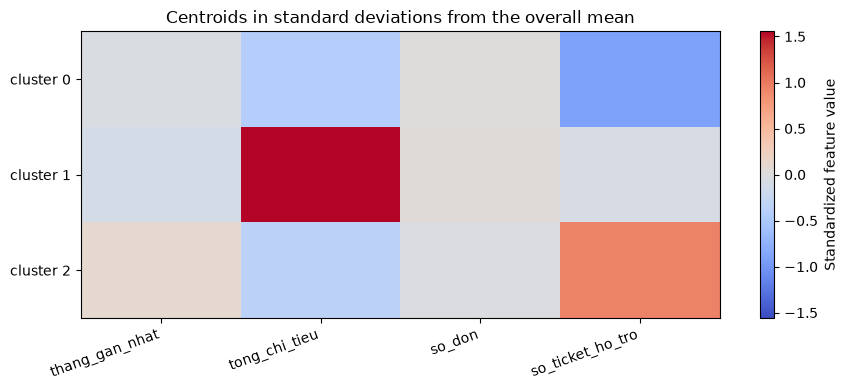

Stability ARI (42 vs 7): 1.0


In [4]:
# TODO 3.1
profile_data = X.assign(cluster=labels)
profile = profile_data.groupby("cluster").mean()
counts = profile_data.groupby("cluster").size().rename("n")
centers_original = scaler.inverse_transform(chosen.cluster_centers_)
print(profile.join(counts).round(2).to_string())
assert counts.sum() == len(X)
assert profile.shape == centers_original.shape == (chosen_k, len(FEATURES))
assert np.isfinite(profile.to_numpy()).all() and np.isfinite(centers_original).all()
# Tolerance-based stopping can leave a small gap; report it instead of asserting equality.
centroid_gap_sd = np.abs((profile.to_numpy() - centers_original) / scaler.scale_).max()
print("Largest centroid / assigned-group-mean gap (standard deviations):", round(float(centroid_gap_sd), 6))

# TODO 3.2
fig, ax = plt.subplots(figsize=(9, 4))
limit = max(1.0, float(np.abs(chosen.cluster_centers_).max()))
im = ax.imshow(chosen.cluster_centers_, cmap="coolwarm", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=20, ha="right")
ax.set_yticks(range(chosen_k), [f"cluster {i}" for i in range(chosen_k)])
ax.set_title("Centroids in standard deviations from the overall mean")
fig.colorbar(im, ax=ax, label="Standardized feature value")
plt.tight_layout()
plt.show()

# TODO 3.3
alternate = KMeans(n_clusters=chosen_k, n_init=10, random_state=7).fit(Z)
print("Stability ARI (42 vs 7):", adjusted_rand_score(labels, alternate.labels_))

**Write 3:** name clusters from the profile table and include units. Why does cluster 0 not mean “good customer”? Why does naming establish no causal relationship?

Dựa trên bảng tổng hợp thống kê của từng cụm tính theo đơn vị gốc, chân dung các nhóm khách hàng được diễn giải như sau:

Cụm 0 (Khách hàng chi tiêu thấp, ít yêu cầu hỗ trợ): Nhóm này có mức chi tiêu trung bình thấp nhất khoảng 5,86 triệu VNĐ và tần suất yêu cầu hỗ trợ rất thấp (0,45 phiếu)

Cụm 1 (Khách hàng VIP, chi tiêu cao): Đây là nhóm khách hàng mang lại giá trị cao nhất với mức tổng chi tiêu vượt trội trung bình 15 triệu VNĐ. Các chỉ số khác như số tháng gần nhất và số đơn hàng duy trì ở mức tương đương cụm 0

Cụm 2 (Khách hàng có nguy cơ rời bỏ cao): Mặc dù có mức chi tiêu trung bình khá khoảng 6,17 triệu VNĐ, nhóm này nổi bật với tần suất yêu cầu hỗ trợ rất cao (2,54 phiếu) và thời gian kể từ lần mua cuối cùng dài nhất (14,85 tháng). Đây là những tín hiệu cảnh báo mức độ không hài lòng

Cần lưu ý, mã cụm 0 chỉ là một định danh (ID) mang tính danh nghĩa do thuật toán K-means khởi tạo, hoàn toàn không đại diện cho giá trị xếp hạng ordinal

Việc gán nhãn nghiệp vụ cho các cụm giúp đơn giản hóa quá trình diễn giải dữ liệu, nhưng tuyệt đối không thiết lập mối quan hệ nhân quả. Chẳng hạn, việc quan sát thấy nhóm khách hàng ở Cụm 2 có số lượng phiếu hỗ trợ cao không giải thích được lý do tại sao họ phàn nàn. Để xác định nguyên nhân cốt lõi nhằm đưa ra biện pháp can thiệp, doanh nghiệp cần thực hiện thêm các nghiên cứu định tính hoặc phân tích nguyên nhân gốc rễ (Root Cause Analysis)

## Task 4 — PCA: compression and visualization (45 min)
**4.1** Fit full PCA (`svd_solver='full'`) on Z. Plot cumulative variance and a 95% line.
Find `n95`: the first index reaching 0.95 plus one. Four weakly correlated features may
require all four components; PCA does not promise dimensionality reduction at 95%.
**4.2** Fit `PCA(n_components=0.95, svd_solver='full')` and check the output width. Print
the first two loading rows. These combine **standardized features**; component signs may flip across versions.
**4.3** Project Z onto two PCs, colored by the **existing 4D cluster labels**. Do not refit
K-means in 2D. Label axes with explained-variance percentages. Compute 2-PC reconstruction MSE in Z space.
**Write 4:** how much variance does the plot retain? Does overlap in 2D prove that clusters
are identical in 4D? Does PCA optimize silhouette or label separation?

Explained ratios: [0.2569 0.2535 0.25   0.2396]
n95: 4 | shape: (1500, 4)
     thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro
PC1          0.4677        -0.0659 -0.4888            0.7335
PC2         -0.6173         0.6493 -0.4053            0.1818


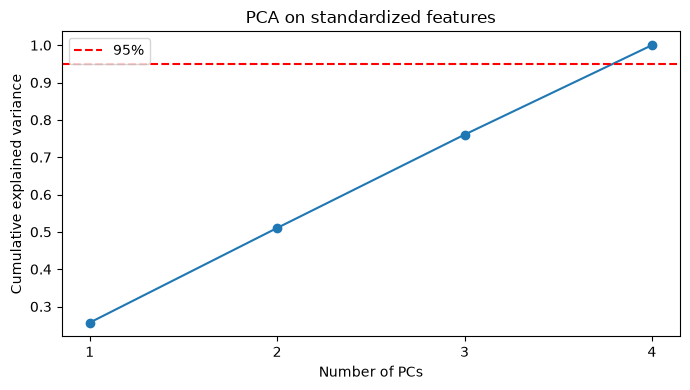

In [5]:
# TODO 4.1–4.2
pca = PCA(svd_solver="full").fit(Z)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n95 = np.argmax(cumulative >= 0.95) + 1
pca95 = PCA(n_components=0.95, svd_solver="full").fit(Z)
compressed = pca95.transform(Z)
assert compressed.shape == (1500, n95)
assert cumulative[n95 - 1] >= 0.95
print("Explained ratios:", pca.explained_variance_ratio_.round(4))
print("n95:", n95, "| shape:", compressed.shape)
print(pd.DataFrame(pca.components_[:2], columns=FEATURES, index=["PC1", "PC2"]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 5), cumulative, "o-")
ax.axhline(0.95, color="red", ls="--", label="95%")
ax.set(xlabel="Number of PCs", ylabel="Cumulative explained variance", title="PCA on standardized features", xticks=range(1, 5))
ax.legend()
plt.tight_layout()
plt.show()

2D retained variance: 0.5103913873086376
2D reconstruction MSE in Z: 0.48960861269136224


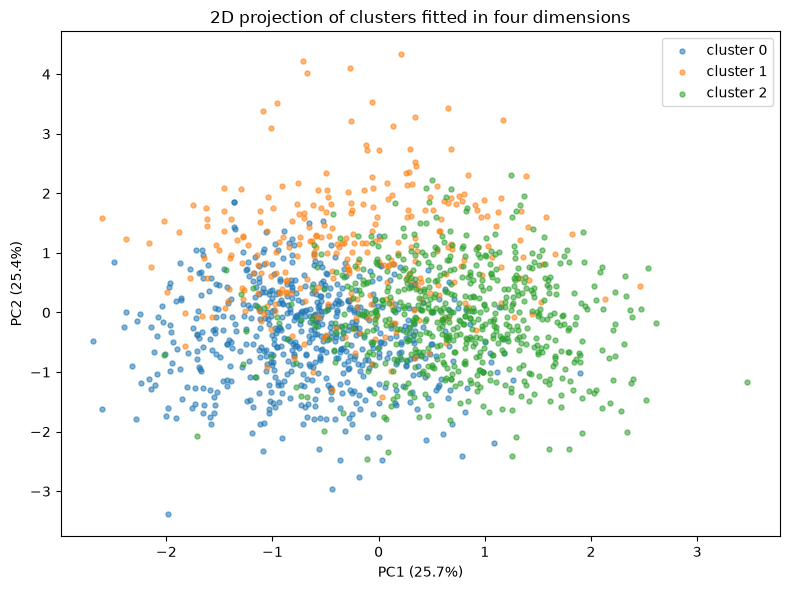

In [6]:
# TODO 4.3
pca2 = PCA(n_components=2, svd_solver="full")
projection = pca2.fit_transform(Z)
reconstructed = pca2.inverse_transform(projection)
reconstruction_mse = np.mean((Z - reconstructed) ** 2)
print("2D retained variance:", pca2.explained_variance_ratio_.sum())
print("2D reconstruction MSE in Z:", reconstruction_mse)
fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(chosen_k):
    mask = labels == cluster_id
    ax.scatter(projection[mask, 0], projection[mask, 1], s=13, alpha=0.55, label=f"cluster {cluster_id}")
ax.set(xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})",
    ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})",
    title="2D projection of clusters fitted in four dimensions")
ax.legend()
plt.tight_layout()
plt.show()
assert projection.shape == (1500, 2)
assert np.isfinite(reconstruction_mse) and reconstruction_mse >= 0

Đồ thị trực quan hóa 2D (chiếu trên PC1 và PC2) bảo toàn được tổng cộng khoảng 51,04% (0.2569 + 0.2535) tổng phương sai của tập dữ liệu ban đầu. Do cả bốn đặc trưng đều có mức độ đóng góp phương sai khá đồng đều, để đạt được ngưỡng 95% phương sai giải thích, mô hình bắt buộc phải giữ lại toàn bộ 4 thành phần chính (n95 = 4)

Sự chồng lấp của các cụm phân loại trên mặt phẳng 2D không đồng nghĩa với việc các cụm này bị hòa lẫn hay không thể phân biệt trong không gian gốc 4D. Hiện tượng chồng lấp này là hệ quả của sự mất mát thông tin (khoảng 49% phương sai bị loại bỏ) khi thực hiện phép chiếu để giảm số chiều không gian

Mục tiêu toán học của kỹ thuật PCA là tạo ra các trục tọa độ mới (các thành phần chính) nhằm tối đa hóa và bảo toàn cấu trúc phương sai toàn cục của dữ liệu. PCA hoàn toàn không được thiết kế để tối ưu hóa hệ số tách biệt (như điểm Silhouette) hay gia tăng khoảng cách giữa các nhãn cụm (đó là vai trò của các thuật toán như Linear Discriminant Analysis - LDA). Do đó, việc trực quan hóa bằng PCA chỉ mang tính chất tham khảo về xu hướng phân bổ tổng thể

## Stretch — When cluster shape defeats K-means (optional)
Generate `make_moons(n_samples=500, noise=0.06, random_state=42)`. Compare K-means k=2
with DBSCAN `eps=0.2, min_samples=5`. Plot partitions with matching axes.
Use synthetic truth only to compute ARI **after fitting**, never to choose eps.
DBSCAN label −1 means noise, not a customer segment.

KMeans noise rows: 0
DBSCAN noise rows: 0


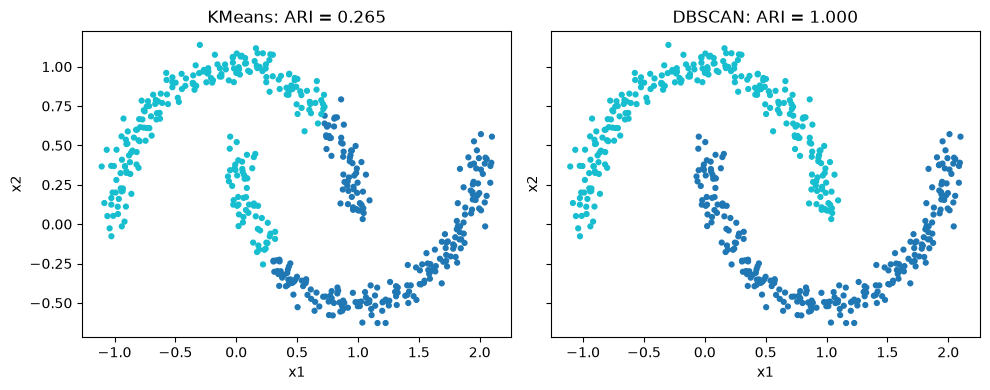

In [7]:
# TODO — optional stretch
moons, truth = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)
moon_models = {
    "KMeans": KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE),
    "DBSCAN": DBSCAN(eps=0.2, min_samples=5)
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, (name, estimator) in zip(axes, moon_models.items()):
    assigned = estimator.fit_predict(moons)
    ax.scatter(moons[:, 0], moons[:, 1], c=assigned, cmap="tab10", s=12)
    ax.set(title=f"{name}: ARI = {adjusted_rand_score(truth, assigned):.3f}", xlabel="x1", ylabel="x2")
    print(name, "noise rows:", int((assigned == -1).sum()))
plt.tight_layout()
plt.show()

## Before submitting
- [x] Complete all four core tasks; remove remaining `...` and `TODO` from required code.
- [x] Answer all four written sections using evidence from your own run.
- [x] Give figures titles, axis labels and legends where needed; retain tables and outputs.
- [x] **Restart & Run All** passes; use seed 42 except in the specified alternate-seed experiment.
- [x] If skipping the stretch, delete its unfinished code cell before Run All and note “not attempted”.
- [x] Rename the notebook with your student ID and submit before leaving the room.